# Tugas Praktikum 3: Classification dengan Ensemble Method & Class Imbalance



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score
)
from imblearn.over_sampling import SMOTE

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.6f}'.format)

def evaluate_predictions(y_true, y_pred, y_score):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (fraud)': precision_score(y_true, y_pred, zero_division=0),
        'Recall (fraud)': recall_score(y_true, y_pred, zero_division=0),
        'F1-score (fraud)': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_score),
        'Average Precision': average_precision_score(y_true, y_score)
    }

In [2]:
df = pd.read_csv('creditcard.csv')
print('Bentuk data:', df.shape)
df.head()

Bentuk data: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.000000,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.620000,0
1,0.000000,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.690000,0
2,1.000000,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.660000,0
3,1.000000,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.500000,0
4,2.000000,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.990000,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

## 1. Distribusi kelas pada label target

Dataset ini sangat tidak seimbang. Karena transaksi fraud jauh lebih sedikit daripada transaksi normal, evaluasi model harus berfokus pada kelas minoritas, bukan hanya pada akurasi keseluruhan.

,Jumlah transaksi,Persentase (%)
Class,,
Normal,284315,99.827251
Fraud,492,0.172749


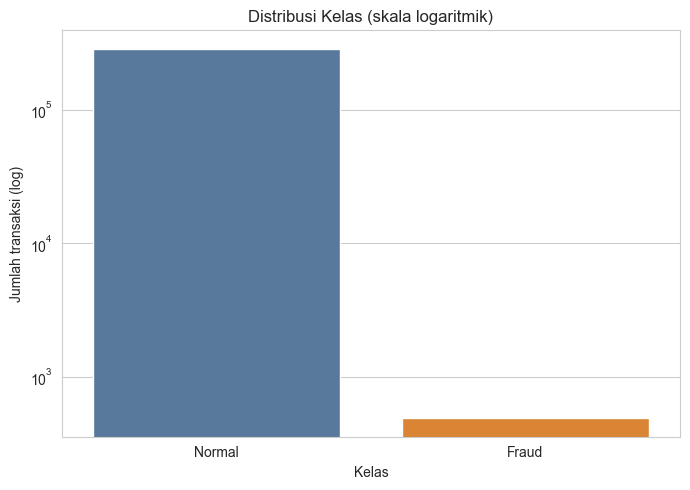

In [4]:
class_counts = df['Class'].value_counts().sort_index()
class_pct = df['Class'].value_counts(normalize=True).sort_index() * 100
class_labels = {0: 'Normal', 1: 'Fraud'}

class_distribution = pd.DataFrame({
    'Jumlah transaksi': class_counts,
    'Persentase (%)': class_pct
})
class_distribution.index = class_distribution.index.map(class_labels)
display(class_distribution)

plt.figure(figsize=(7, 5))
sns.barplot(
    x=class_distribution.index,
    y=class_distribution['Jumlah transaksi'],
    hue=class_distribution.index,
    palette=['#4C78A8', '#F58518'],
    legend=False
)
plt.yscale('log')
plt.title('Distribusi Kelas (skala logaritmik)')
plt.xlabel('Kelas')
plt.ylabel('Jumlah transaksi (log)')
plt.tight_layout()
plt.show()

## 2. Pemisahan data latih dan data uji

Data dibagi dengan rasio 80:20 dan `stratify=y`, sehingga proporsi transaksi fraud tetap terjaga pada data latih dan data uji. Pemisahan dilakukan sebelum resampling untuk mencegah data sintetis masuk ke data uji.

In [5]:
X = df.drop(columns='Class')
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

split_summary = pd.DataFrame({
    'Jumlah data': [len(y_train), len(y_test)],
    'Jumlah fraud': [int(y_train.sum()), int(y_test.sum())],
    'Persentase fraud (%)': [
        y_train.mean() * 100,
        y_test.mean() * 100
    ]
}, index=['Data latih', 'Data uji'])
display(split_summary)

,Jumlah data,Jumlah fraud,Persentase fraud (%)
Data latih,227845,394,0.172925
Data uji,56962,98,0.172045


## 3. Baseline Random Forest tanpa penanganan imbalance


In [6]:
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_baseline.fit(X_train, y_train)
y_pred_baseline = rf_baseline.predict(X_test)
y_prob_baseline = rf_baseline.predict_proba(X_test)[:, 1]

metrics_baseline = evaluate_predictions(
    y_test, y_pred_baseline, y_prob_baseline
)
pd.Series(metrics_baseline, name='Random Forest tanpa penanganan')

Accuracy            0.999596
Precision (fraud)   0.941176
Recall (fraud)      0.816327
F1-score (fraud)    0.874317
ROC-AUC             0.963027
Average Precision   0.873391
Name: Random Forest tanpa penanganan, dtype: float64

## 4. Cost-sensitive learning dengan `class_weight`


In [7]:
rf_weighted = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

rf_weighted.fit(X_train, y_train)
y_pred_weighted = rf_weighted.predict(X_test)
y_prob_weighted = rf_weighted.predict_proba(X_test)[:, 1]

metrics_weighted = evaluate_predictions(
    y_test, y_pred_weighted, y_prob_weighted
)
pd.Series(metrics_weighted, name='Random Forest + class_weight')

Accuracy            0.999508
Precision (fraud)   0.960526
Recall (fraud)      0.744898
F1-score (fraud)    0.839080
ROC-AUC             0.952908
Average Precision   0.854200
Name: Random Forest + class_weight, dtype: float64

## 5. Oversampling data latih dengan SMOTE



In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_scaled, y_train
)

resampled_counts = y_train_resampled.value_counts().sort_index()
resampled_counts.index = resampled_counts.index.map(class_labels)
display(resampled_counts.rename('Jumlah setelah SMOTE').to_frame())

rf_smote = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_smote.fit(X_train_resampled, y_train_resampled)
y_pred_smote = rf_smote.predict(X_test_scaled)
y_prob_smote = rf_smote.predict_proba(X_test_scaled)[:, 1]

metrics_smote = evaluate_predictions(
    y_test, y_pred_smote, y_prob_smote
)
pd.Series(metrics_smote, name='Random Forest + SMOTE')

,Jumlah setelah SMOTE
Class,
Normal,227451
Fraud,227451


Accuracy            0.999491
Precision (fraud)   0.870968
Recall (fraud)      0.826531
F1-score (fraud)    0.848168
ROC-AUC             0.968448
Average Precision   0.872440
Name: Random Forest + SMOTE, dtype: float64

## 6. Perbandingan performa

,Accuracy,Precision (fraud),Recall (fraud),F1-score (fraud),ROC-AUC,Average Precision
RF tanpa penanganan,0.999600,0.941200,0.816300,0.874300,0.963000,0.873400
RF + class_weight,0.999500,0.960500,0.744900,0.839100,0.952900,0.854200
RF + SMOTE,0.999500,0.871000,0.826500,0.848200,0.968400,0.872400


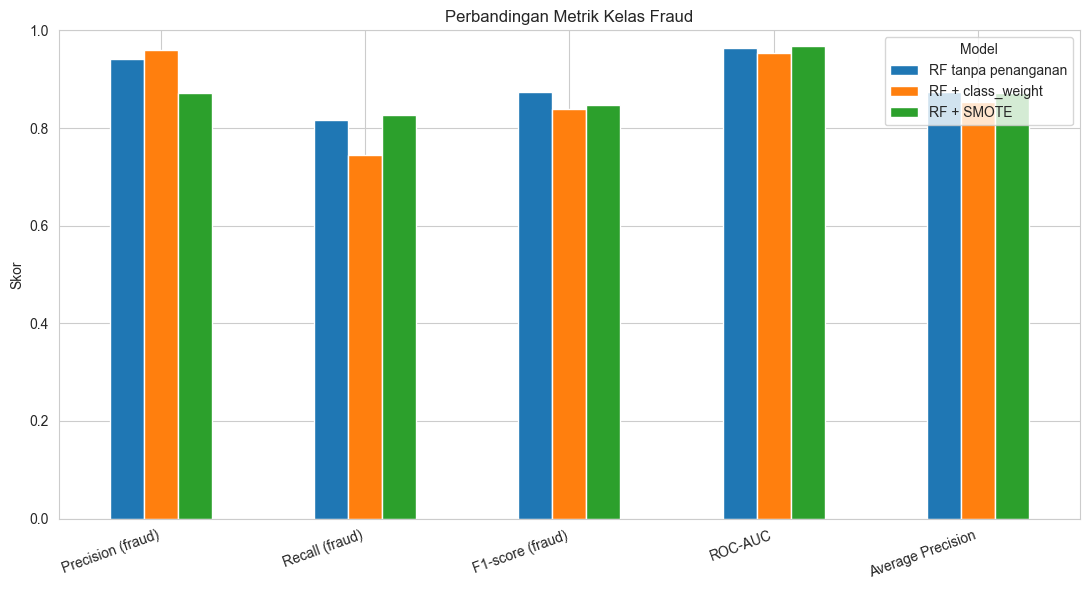

In [9]:
results = pd.DataFrame({
    'RF tanpa penanganan': metrics_baseline,
    'RF + class_weight': metrics_weighted,
    'RF + SMOTE': metrics_smote
}).T

display(results.round(4))

metrics_to_plot = [
    'Precision (fraud)', 'Recall (fraud)', 'F1-score (fraud)',
    'ROC-AUC', 'Average Precision'
]
results[metrics_to_plot].T.plot(kind='bar', figsize=(11, 6))
plt.ylabel('Skor')
plt.title('Perbandingan Metrik Kelas Fraud')
plt.ylim(0, 1)
plt.xticks(rotation=20, ha='right')
plt.legend(title='Model')
plt.tight_layout()
plt.show()

## 7. Confusion matrix

Baris menunjukkan label sebenarnya dan kolom menunjukkan prediksi. Perhatikan jumlah fraud yang terlewat (FN) dan transaksi normal yang keliru ditandai fraud (FP).

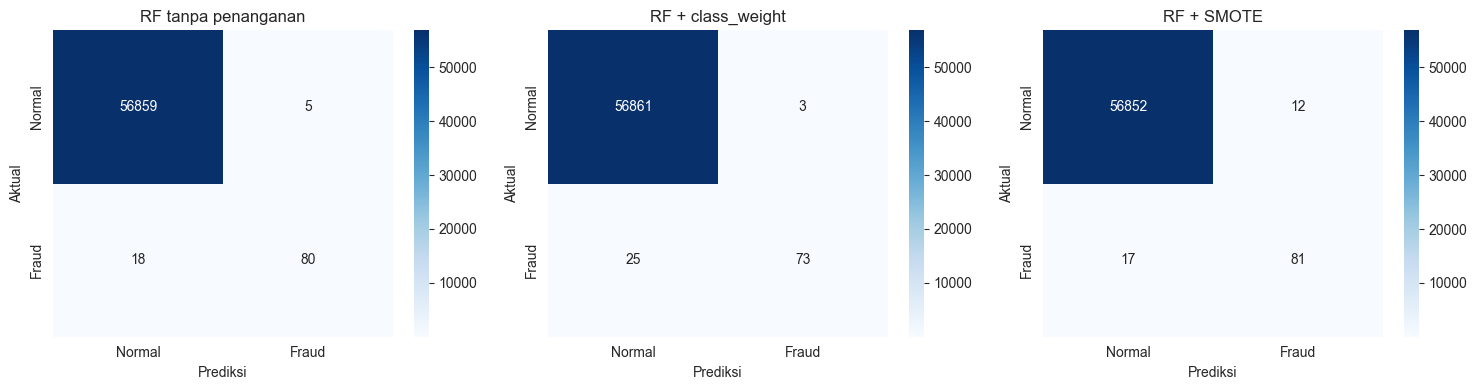

In [10]:
confusion_matrices = [
    ('RF tanpa penanganan', confusion_matrix(y_test, y_pred_baseline)),
    ('RF + class_weight', confusion_matrix(y_test, y_pred_weighted)),
    ('RF + SMOTE', confusion_matrix(y_test, y_pred_smote))
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, (title, matrix) in zip(axes, confusion_matrices):
    sns.heatmap(
        matrix,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Normal', 'Fraud'],
        yticklabels=['Normal', 'Fraud'],
        ax=axis
    )
    axis.set_title(title)
    axis.set_xlabel('Prediksi')
    axis.set_ylabel('Aktual')

plt.tight_layout()
plt.show()

## 8. Kesimpulan dan interpretasi

Dari 284.807 transaksi, hanya 492 (0,173%) yang fraud. Bahkan model sederhana yang selalu menebak “normal” akan memperoleh accuracy 99,827%, tetapi recall fraud-nya 0%. Karena itu, accuracy yang tinggi saja tidak cukup untuk menyatakan model berhasil.

Pada data uji terdapat 98 transaksi fraud. Random Forest tanpa penanganan memperoleh precision 0,9412, recall 0,8163, F1-score 0,8743, ROC-AUC 0,9630, dan Average Precision 0,8734. Confusion matrix-nya menunjukkan 80 fraud terdeteksi, 18 terlewat, dan 5 transaksi normal salah ditandai fraud.

Model dengan class_weight='balanced' memiliki precision tertinggi (0,9605) dan hanya 3 false positive, tetapi recall-nya lebih rendah (0,7449; 25 fraud terlewat). SMOTE dengan fitur yang sudah diskalakan memberi recall tertinggi (0,8265) dan ROC-AUC tertinggi (0,9684), tetapi mendeteksi hanya satu fraud lebih banyak daripada baseline sambil menambah false positive dari 5 menjadi 12. F1-score SMOTE (0,8482) dan Average Precision (0,8724) juga sedikit di bawah baseline. Jadi, SMOTE tidak unggul pada semua metrik; pemilihannya bergantung pada biaya fraud yang terlewat dibanding alarm palsu.

Kesimpulan ini perlu dibaca dengan hati-hati karena data uji hanya memuat 98 kasus fraud; satu kasus saja mengubah recall sekitar 1,02 poin persentase. Hasil sebelumnya juga bukan perbandingan yang tepat: baseline lama sudah memakai class_weight='balanced', sedangkan SMOTE dilakukan pada fitur yang belum diskalakan. Notebook ini memperbaiki perbandingan dengan memisahkan baseline murni, cost-sensitive learning, dan SMOTE yang skalernya hanya di-fit pada data latih. Semua model dievaluasi pada data uji asli yang sama. Threshold prediksi masih bawaan 0,5 dan belum dioptimalkan.